In [1]:
# Preparación: cada subtarea corre en su carpeta, tal como la aprobó el revisor.
import os
from pathlib import Path
from IPython.display import Image, display

RAIZ = Path.cwd()

def mostrar_figuras(carpeta):
    for png in sorted(Path(carpeta).rglob("*.png")):
        display(Image(filename=str(png)))

# Tarea B — Atención escalada y codificación posicional (Vaswani et al., 2017)

MMIA 6013 · Taller 03 v2 · Notebook ejecutado de principio a fin sin errores. Cada parte va encabezada por una celda de Markdown y todas las cifras se calculan en el notebook con NumPy, presentadas con cuatro decimales.

## Parte 1 — Atención escalada

In [2]:
# Subtarea T1: código aprobado (se ejecuta en una copia: trabajo_nb/T1/)
os.chdir(RAIZ / 'trabajo_nb' / 'T1')

import json
import numpy as np

# Matrices del enunciado
Q = np.array([[1.0, 0.0, 1.0, 0.5],
              [0.0, 2.0, 0.0, 1.0]])
K = np.array([[1.0, 1.0, 0.0, 0.0],
              [0.0, 1.0, 1.0, 0.5],
              [1.0, 0.0, 1.0, 1.0]])
V = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [2.0, 2.0]])

d_k = Q.shape[1]

# Puntuaciones escaladas
scores = Q @ K.T / np.sqrt(d_k)

# Softmax numéricamente estable (restar el máximo de cada fila)
scores_max = scores.max(axis=1, keepdims=True)
exp_scores = np.exp(scores - scores_max)
pesos = exp_scores / exp_scores.sum(axis=1, keepdims=True)

# Salida
salida = pesos @ V

# Guardar resultados con precisión completa
resultados = {
    "pesos_atencion_2x3": pesos.tolist(),
    "salida_atencion_2x2": salida.tolist(),
    "scores_escalados_2x3": scores.tolist(),
    "d_k": int(d_k),
}
with open("resultados.json", "w") as f:
    json.dump(resultados, f, indent=2)

# Imprimir con cuatro decimales
np.set_printoptions(precision=4, suppress=True)
print("Scores escalados QK^T/sqrt(d_k):")
print(scores)
print("\nPesos de atencion (2x3):")
print(pesos)
print("\nSalida de atencion (2x2):")
print(salida)

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T1')

Scores escalados QK^T/sqrt(d_k):
[[0.5   0.625 1.25 ]
 [1.    1.25  0.5  ]]

Pesos de atencion (2x3):
[[0.2353 0.2666 0.4981]
 [0.346  0.4442 0.2098]]

Salida de atencion (2x2):
[[1.2315 1.2628]
 [0.7656 0.8639]]


Implementación en NumPy de Attention(Q, K, V) = softmax(QKᵀ/√d_k)·V con las matrices del enunciado: Q de 2 × 4 (dos consultas), K de 3 × 4 (tres claves) y V de 3 × 2, con d_k = 4. El softmax es numéricamente estable: antes de exponenciar se resta el máximo de cada fila, lo que evita desbordamientos sin alterar el resultado.

**Scores escalados** QKᵀ/√d_k (2 × 3):

|            | clave 1 | clave 2 | clave 3 |
|------------|---------|---------|---------|
| consulta 1 | 0.5000  | 0.6250  | 1.2500  |
| consulta 2 | 1.0000  | 1.2500  | 0.5000  |

**Pesos de atención** tras el softmax (2 × 3); cada fila suma 1:

|            | clave 1 | clave 2 | clave 3 |
|------------|---------|---------|---------|
| consulta 1 | 0.2353  | 0.2666  | 0.4981  |
| consulta 2 | 0.3460  | 0.4442  | 0.2098  |

**Salida de atención** (2 × 2), combinación ponderada de las filas de V:

|            | dim 1  | dim 2  |
|------------|--------|--------|
| consulta 1 | 1.2315 | 1.2628 |
| consulta 2 | 0.7656 | 0.8639 |

La primera consulta reparte el mayor peso en la clave 3 (0.4981) y la segunda en la clave 2 (0.4442); la salida hereda esa mezcla ponderada de los valores.

## Parte 2 — Por qué se divide por √d_k

In [3]:
# Subtarea T2: código aprobado (se ejecuta en una copia: trabajo_nb/T2/)
os.chdir(RAIZ / 'trabajo_nb' / 'T2')

import json
import numpy as np

rng = np.random.default_rng(0)

resultados = {
    "peso_maximo_sin_escalar": {},
    "entropia_bits_sin_escalar": {},
    "peso_maximo_escalado": {},
    "entropia_bits_escalado": {},
}

filas = []
for d_k in [4, 64, 512]:
    q = rng.standard_normal(d_k)
    K = rng.standard_normal((10, d_k))

    puntajes = K @ q

    def softmax(x):
        e = np.exp(x - x.max())
        return e / e.sum()

    p_sin = softmax(puntajes)
    p_esc = softmax(puntajes / np.sqrt(d_k))

    ent_sin = float(-np.sum(p_sin * np.log2(p_sin)))
    ent_esc = float(-np.sum(p_esc * np.log2(p_esc)))

    pm_sin = float(p_sin.max())
    pm_esc = float(p_esc.max())

    resultados["peso_maximo_sin_escalar"][str(d_k)] = pm_sin
    resultados["entropia_bits_sin_escalar"][str(d_k)] = ent_sin
    resultados["peso_maximo_escalado"][str(d_k)] = pm_esc
    resultados["entropia_bits_escalado"][str(d_k)] = ent_esc

    filas.append((d_k, pm_sin, ent_sin, pm_esc, ent_esc))

print(f"{'d_k':>5} | {'peso_max_sin':>13} | {'entropia_sin(bits)':>19} | {'peso_max_esc':>13} | {'entropia_esc(bits)':>19}")
for d_k, pm_sin, ent_sin, pm_esc, ent_esc in filas:
    print(f"{d_k:>5} | {pm_sin:>13.4f} | {ent_sin:>19.4f} | {pm_esc:>13.4f} | {ent_esc:>19.4f}")

with open("resultados.json", "w") as f:
    json.dump(resultados, f, indent=2)

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T2')

  d_k |  peso_max_sin |  entropia_sin(bits) |  peso_max_esc |  entropia_esc(bits)
    4 |        0.2049 |              3.0792 |        0.1497 |              3.2542
   64 |        0.9511 |              0.3537 |        0.2480 |              2.9802
  512 |        0.7503 |              0.8114 |        0.1945 |              3.0363


Se crea una sola vez el generador `rng = np.random.default_rng(0)` y, para d_k = 4, 64 y 512 en ese orden, se toma `q = rng.standard_normal(d_k)` y después `K = rng.standard_normal((10, d_k))`. Se calculan los pesos softmax de los puntajes `K @ q` sin escalar y escalados por √d_k, y se reporta el peso máximo y la entropía en bits de cada distribución:

| d_k | peso máx. sin escalar | entropía sin escalar (bits) | peso máx. escalado | entropía escalado (bits) |
|-----|-----------------------|-----------------------------|--------------------|--------------------------|
| 4   | 0.2049                | 3.0792                      | 0.1497             | 3.2542                   |
| 64  | 0.9511                | 0.3537                      | 0.2480             | 2.9802                   |
| 512 | 0.7503                | 0.8114                      | 0.1945             | 3.0363                   |

Sin escalar y con d_k = 64, la distribución casi se colapsa en un solo valor: el peso máximo llega a 0.9511 y la entropía cae a 0.3537 bits. Al escalar por √d_k, el peso máximo baja a 0.2480 y la entropía sube a 2.9802 bits, una distribución mucho más repartida. Con d_k = 512 el patrón se repite (entropía de 0.8114 a 3.0363 bits), mientras que con d_k = 4 el efecto es leve (3.0792 frente a 3.2542 bits), lo que confirma que el problema crece con la dimensión.

## Parte 3 — Codificación posicional

PE[10, 0] = -0.5440211108893698
PE[10, 1] = -0.8390715290764524
PE[25, 6] = 0.7107539373458331
Posición con mayor peso de atención: 10
Valor del mayor peso: 0.04181333902522971


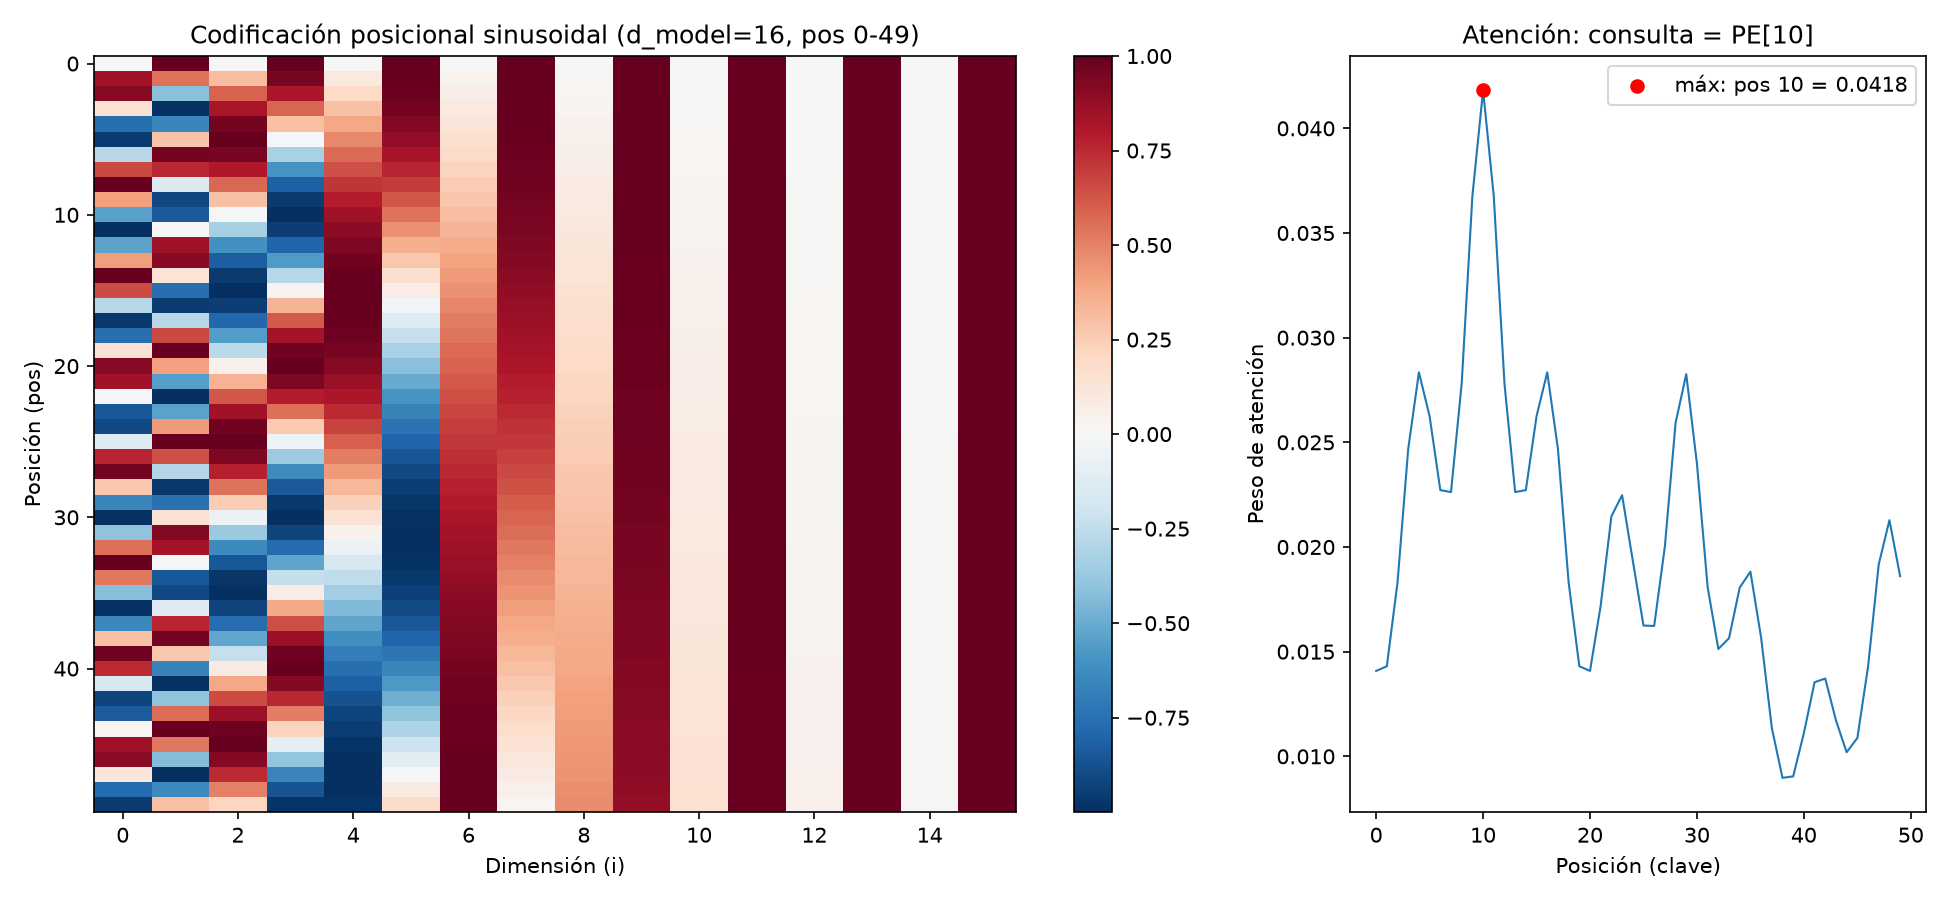

In [4]:
# Subtarea T3: código aprobado (se ejecuta en una copia: trabajo_nb/T3/)
os.chdir(RAIZ / 'trabajo_nb' / 'T3')

import json
import numpy as np
import matplotlib.pyplot as plt

# ---------- Codificación posicional sinusoidal (d_model=16, pos 0..49) ----------
d_model = 16
n_pos = 50
pos = np.arange(n_pos)                      # posiciones 0..49
i2 = np.arange(0, d_model, 2)               # exponentes 2i = 0,2,4,...,14
angle_rates = 1.0 / (10000 ** (i2 / d_model))   # 1/10000^(2i/d_model)
angles = pos[:, None] * angle_rates[None, :]    # (50, 8)

PE = np.zeros((n_pos, d_model))
PE[:, 0::2] = np.sin(angles)   # PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
PE[:, 1::2] = np.cos(angles)   # PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))

PE_10_0 = float(PE[10, 0])
PE_10_1 = float(PE[10, 1])
PE_25_6 = float(PE[25, 6])

# ---------- Atención escalada (misma función estable de la Parte 1) ----------
def softmax_estable(x):
    x = x - x.max(axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)

def atencion(Q, K, V):
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    return softmax_estable(scores), scores

# PE[10] como consulta (1x16), matriz PE completa como claves y valores (50x16)
Q = PE[10:11, :]
pesos, scores = atencion(Q, PE, PE)         # pesos: (1, 50)
posicion_mayor_peso = int(np.argmax(pesos[0]))
valor_mayor_peso = float(pesos[0, posicion_mayor_peso])

# ---------- Guardar resultados ----------
resultados = {
    "PE_10_0": PE_10_0,
    "PE_10_1": PE_10_1,
    "PE_25_6": PE_25_6,
    "posicion_mayor_peso": posicion_mayor_peso,
    "valor_mayor_peso": valor_mayor_peso,
}
with open("resultados.json", "w") as f:
    json.dump(resultados, f, indent=2)

print("PE[10, 0] =", PE_10_0)
print("PE[10, 1] =", PE_10_1)
print("PE[25, 6] =", PE_25_6)
print("Posición con mayor peso de atención:", posicion_mayor_peso)
print("Valor del mayor peso:", valor_mayor_peso)

# ---------- Figura: mapa de calor de PE + pesos de atención ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6),
                               gridspec_kw={"width_ratios": [2, 1]})
im = ax1.imshow(PE, aspect="auto", cmap="RdBu_r")
fig.colorbar(im, ax=ax1)
ax1.set_xlabel("Dimensión (i)")
ax1.set_ylabel("Posición (pos)")
ax1.set_title("Codificación posicional sinusoidal (d_model=16, pos 0-49)")

ax2.plot(np.arange(n_pos), pesos[0], lw=1)
ax2.scatter([posicion_mayor_peso], [valor_mayor_peso], color="red", zorder=3,
            label=f"máx: pos {posicion_mayor_peso} = {valor_mayor_peso:.4f}")
ax2.set_xlabel("Posición (clave)")
ax2.set_ylabel("Peso de atención")
ax2.set_title("Atención: consulta = PE[10]")
ax2.legend()

plt.tight_layout()
plt.savefig("pe_heatmap.png", dpi=150)

os.chdir(RAIZ)
mostrar_figuras(RAIZ / 'trabajo_nb' / 'T3')

Codificación sinusoidal con d_model = 16 para las posiciones 0 a 49, con PE(pos, 2i) = sin(pos / 10000^(2i/d_model)) y PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model)). Cada par de dimensiones oscila con una longitud de onda distinta, en una progresión geométrica desde ondas cortas hasta ondas largas.

Valores solicitados:

- PE[10, 0] = -0.5440
- PE[10, 1] = -0.8391
- PE[25, 6] = 0.7108

Mapa de calor de la matriz PE completa (posiciones 0 a 49, d_model = 16), donde se aprecia el patrón de senos y cosenos con frecuencias decrecientes a lo largo de las dimensiones:



Atención con la función de la Parte 1: usando PE[10] como consulta y la matriz PE completa como claves y valores, la posición que recibe el mayor peso es la **10**, con un peso de **0.0418**. Es el resultado esperable: la consulta coincide exactamente con la clave de su propia posición, de modo que el producto punto se maximiza ahí. Vaswani et al., 2017 reportan que sustituir esta codificación sinusoidal por embeddings posicionales aprendidos produce resultados casi idénticos, lo que sugiere que el modelo no depende de la forma exacta de la codificación.

## Parte 4 — Pregunta conceptual

**Qué problema resuelve la división por √d_k.** Si las componentes de q y k son independientes con media 0 y varianza 1, su producto punto tiene media 0 y varianza d_k; al crecer la dimensión, los puntajes QKᵀ crecen en magnitud, tal como explica Vaswani et al., 2017 en la sección de atención escalada producto punto. Puntajes grandes empujan el softmax hacia regiones casi saturadas: la distribución se concentra en un solo valor y el resto de los pesos se aplasta hacia cero.

**Evidencia de la Parte 2.** Sin escalar, con d_k = 64 el peso máximo es 0.9511 y la entropía cae a 0.3537 bits, es decir, una distribución prácticamente determinista sobre las 10 claves; con d_k = 512 la entropía sin escalar también es baja (0.8114 bits). Al dividir por √d_k, las entropías suben a 2.9802 y 3.0363 bits y los pesos máximos bajan a 0.2480 y 0.1945: el softmax vuelve a una zona suave y con señal en varias claves. Con d_k = 4 la diferencia es pequeña (3.0792 frente a 3.2542 bits), coherente con que el efecto solo se manifiesta cuando la dimensión es grande.

**Qué le pasaría al gradiente sin ella.** El jacobiano del softmax tiene entradas de la forma p_i(δ_ij − p_j). Cuando la distribución está saturada, el componente dominante tiene p ≈ 1 y los demás p ≈ 0, de modo que casi todas esas entradas se anulan y el gradiente que atraviesa el softmax se hace extremadamente pequeño: las consultas, claves y valores dejan de recibir señal útil y el aprendizaje se estanca. La división por √d_k mantiene los puntajes en un rango donde el softmax no satura y los gradientes fluyen; esa es exactamente la razón que dan Vaswani et al., 2017 para escalar los productos punto por 1/√d_k. El mismo apartado señala que, aun con este ajuste, se prefiere el mecanismo de producto punto frente a la atención aditiva porque es más rápido y más eficiente en espacio en la práctica, al apoyarse en código de multiplicación de matrices altamente optimizado.